# Разреженный оптический поток Lucas–Kanade

Разберём готовый PyrLK в OpenCV и простую собственную оценку для выбранных точек. Затем применим OpenCV к видео и проверим соответствия вперёд–назад.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

# Работает при запуске из корня репозитория и из папки этого notebook.
PROJECT = Path("optical_flow_lesson")
if not PROJECT.is_dir():
    PROJECT = Path("lessons/lesson_02/optical_flow_lesson")
if not PROJECT.is_dir():
    PROJECT = Path(".")
sys.path.insert(0, str(PROJECT.resolve()))

import cv2
import numpy as np
import matplotlib.pyplot as plt

DATA = PROJECT / "data"  # Пути отсчитываются от папки notebook.
OUTPUTS = PROJECT / "outputs"

## Изображения и выбор точек

Создадим пару с известным переносом `(dx, dy)`. `goodFeaturesToTrack` выбирает углы: в их окрестностях яркость меняется по двум направлениям. На ровном участке или прямой границе обе компоненты движения определить труднее.

Координаты точек идут в порядке `(x, y)`, индексы изображения — `[y, x]`. OpenCV возвращает точки `float32` формы `(N, 1, 2)`.

Точки: (80, 1, 2) float32


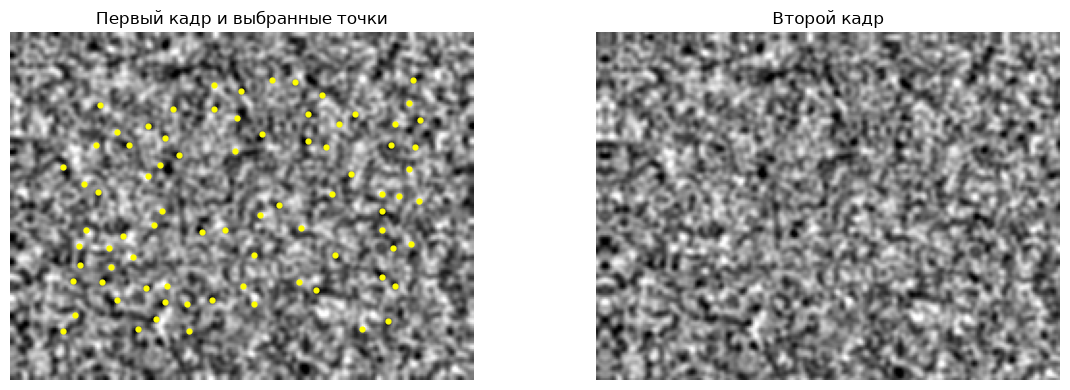

In [2]:
dx, dy = 4, 2  # Перенос вправо и вниз, px. Попробуйте также (12, 6).
rng = np.random.default_rng(7)
noise = rng.uniform(0, 255, (180, 240)).astype(np.float32)
previous = cv2.GaussianBlur(noise, (0, 0), 1.4)  # Размер ядра вычисляется из sigma=1.4.
previous = np.clip((previous - 128) * 3 + 128, 0, 255).astype(np.uint8)
current = cv2.warpAffine(
    previous,
    np.float32([[1, 0, dx], [0, 1, dy]]),  # Матрица переноса 2×3.
    (240, 180),                          # Размер выхода: ширина, высота.
    borderMode=cv2.BORDER_REFLECT_101,    # Дополняем открывшиеся края отражением.
)
mask = np.zeros_like(previous)
mask[24:-24, 24:-24] = 255  # Выбираем точки вдали от отражённых краёв.
points = cv2.goodFeaturesToTrack(
    previous,           # Серый кадр uint8.
    maxCorners=80,      # Верхняя граница числа точек.
    qualityLevel=0.02,  # Порог относительно качества сильнейшего угла.
    minDistance=8,      # Минимальное расстояние между точками, px.
    mask=mask,          # Ненулевые позиции разрешают выбор точки.
)
if points is None:
    raise ValueError("Не найдены характерные точки")
print("Точки:", points.shape, points.dtype)
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(previous, cmap="gray", vmin=0, vmax=255)
axes[0].scatter(points[:, 0, 0], points[:, 0, 1], s=12, c="yellow")
axes[0].set_title("Первый кадр и выбранные точки")
axes[1].imshow(current, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Второй кадр")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## PyrLK без пирамиды и с ней

`winSize` — размер локального окна, а не жёсткая граница смещения. Большое окно даёт больше информации, но может смешивать разные движения. `maxLevel=0` отключает пирамиду, `3` разрешает уровни 0…3; на маленьких изображениях OpenCV может построить меньше уровней.

`criteria` останавливает уточнение по любому включённому условию: достигнут предел итераций или поправка позиции стала меньше epsilon. Epsilon не гарантирует такую же точность ответа.

`status=1` означает принятие результата, а не доказанную правильность. При `flags=0` массив `error` измеряет разность яркостей окон; для отвергнутых точек он не определён. EPE ниже считается отдельно по известному переносу.

L0: принято 80/80
Медианный вектор: [3.9999542 1.9999752]
Медиана EPE: 0.0001 px
L3: принято 80/80
Медианный вектор: [3.999981  1.9999962]
Медиана EPE: 0.0002 px


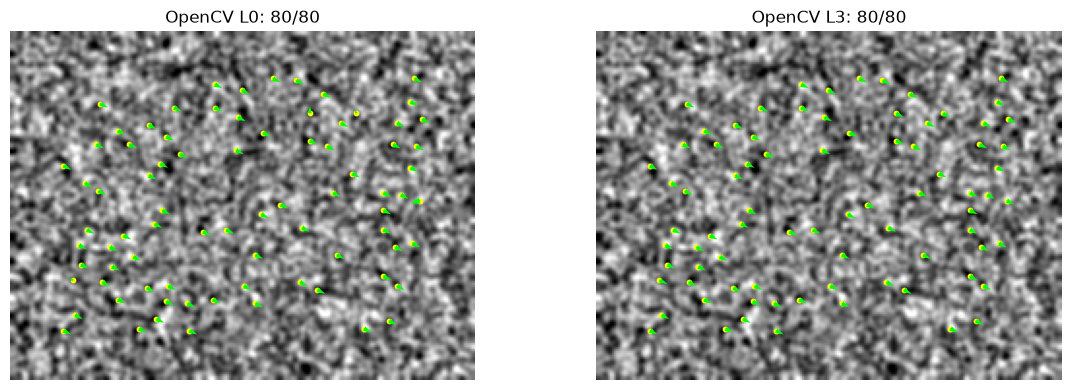

In [3]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, level in zip(axes, [0, 3]):
    next_points, status, error = cv2.calcOpticalFlowPyrLK(
        previous, current,  # Серые кадры одинакового размера и типа.
        points, None,       # Начальные координаты; выходной массив создаст OpenCV.
        winSize=(21, 21),   # Размер окна на каждом уровне.
        maxLevel=level,     # Максимальный индекс уровня, не число уровней.
        criteria=(
            cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
            30,    # Не более 30 уточнений на уровне.
            0.01,  # Остановка при поправке меньше 0.01 px текущего уровня.
        ),
        flags=0,                # Без переданного начального приближения.
        minEigThreshold=1e-4,    # Порог информативности окна по двум направлениям.
    )
    valid = status.ravel() == 1
    start = points[valid, 0]
    end = next_points[valid, 0]
    movement = end - start  # Векторы (u, v), а не новые координаты.
    epe = np.linalg.norm(movement - [dx, dy], axis=1)
    print(f"L{level}: принято {valid.sum()}/{len(points)}")
    if valid.any():
        print("Медианный вектор:", np.median(movement, axis=0))
        print(f"Медиана EPE: {np.median(epe):.4f} px")
    axis.imshow(previous, cmap="gray", vmin=0, vmax=255)
    axis.scatter(start[:, 0], start[:, 1], s=10, c="yellow")
    # xy учитывает направление осей изображения; scale=1 сохраняет длины в px.
    axis.quiver(start[:, 0], start[:, 1], movement[:, 0], movement[:, 1],
                angles="xy", scale_units="xy", scale=1, color="lime")
    axis.set_title(f"OpenCV L{level}: {valid.sum()}/{len(points)}")
    axis.axis("off")
plt.tight_layout()
plt.show()

## Своя минимальная версия LK

Яркость примерно сохраняется: `Ix*u + Iy*v = -It`. Одна точка даёт одно уравнение, окно — много уравнений с двумя неизвестными. Собираем градиенты в матрицу `A` и решаем `(A.T @ A) movement = -A.T @ It`.

Ниже один шаг линеаризации около нулевого движения: без пирамиды и итеративного совмещения. Поэтому проверяем малый перенос `(0.5, 0.25)`. Маска `valid` проверяет информативность окна, но не гарантирует точность найденного смещения.

In [4]:
def lucas_kanade(previous, current, points, window_size=21):
    """Один линейный шаг LK для выбранных точек, без пирамиды и итераций."""
    first = previous.astype(np.float32) / 255
    second = current.astype(np.float32) / 255
    # Собель: float32, производные по x и y, ядро 3×3, нормировка 1/8.
    gx = cv2.Sobel(first, cv2.CV_32F, 1, 0, ksize=3, scale=1 / 8)
    gy = cv2.Sobel(first, cv2.CV_32F, 0, 1, ksize=3, scale=1 / 8)
    temporal = second - first
    points = np.asarray(points, dtype=np.float32).reshape(-1, 2)
    next_points = points.copy()
    valid = np.zeros(len(points), dtype=bool)
    radius = window_size // 2 + 1
    height, width = first.shape
    for index, (x, y) in enumerate(points):
        # Полное окно и производные должны помещаться в исходный кадр.
        if not (radius <= x < width - radius and radius <= y < height - radius):
            continue
        center = (float(x), float(y))
        size = (window_size, window_size)
        # getRectSubPix вырезает окно с дробным центром, интерполируя значения.
        ix = cv2.getRectSubPix(gx, size, center).ravel()
        iy = cv2.getRectSubPix(gy, size, center).ravel()
        it = cv2.getRectSubPix(temporal, size, center).ravel()
        A = np.column_stack([ix, iy])  # По уравнению Ix*u + Iy*v = -It на пиксель.
        H = A.T @ A                   # Матрица системы 2×2.
        if np.linalg.eigvalsh(H)[0] / window_size**2 < 1e-5:
            continue  # Ровный участок или граница не задают обе компоненты.
        movement = np.linalg.solve(H, -A.T @ it)  # Наименьшие квадраты, без inverse.
        end = points[index] + movement
        if np.isfinite(end).all() and 0 <= end[0] < width and 0 <= end[1] < height:
            next_points[index] = end
            valid[index] = True
    return next_points, valid

# Малый перенос: один линейный шаг рассчитан на малое движение.
own_shift = np.float32([0.5, 0.25])
small_current = cv2.warpAffine(
    previous, np.float32([[1, 0, own_shift[0]], [0, 1, own_shift[1]]]),
    (previous.shape[1], previous.shape[0]), borderMode=cv2.BORDER_REFLECT_101,
)
own_points, own_valid = lucas_kanade(previous, small_current, points)
cv_points, cv_status, _ = cv2.calcOpticalFlowPyrLK(
    previous, small_current, points, None, winSize=(21, 21), maxLevel=0,
    criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01),
)
# Ошибки обоих методов измеряем на одном наборе принятых точек.
common = own_valid & (cv_status.ravel() == 1)
for name, found in [("Своя LK", own_points), ("OpenCV L0", cv_points[:, 0])]:
    if common.any():
        movement = found[common] - points[common, 0]
        error = np.linalg.norm(movement - own_shift, axis=1)
        print(name, "медианный вектор:", np.median(movement, axis=0),
              f"EPE: {np.median(error):.4f} px; точек: {common.sum()}")
    else:
        print(name, "нет общих принятых точек")


Своя LK медианный вектор: [0.5134697  0.24872017] EPE: 0.0160 px; точек: 80
OpenCV L0 медианный вектор: [0.5005188 0.2501793] EPE: 0.0093 px; точек: 80


## Применение к видео

Измените `frame` и `gap`, затем повторно выполните ячейку. `gap` — расстояние между исходными кадрами; вектор измеряется в пикселях за этот интервал. Точки для каждой пары выбираются заново: непрерывные траектории здесь не ведутся. На видео истинный поток неизвестен, поэтому EPE не считаем.

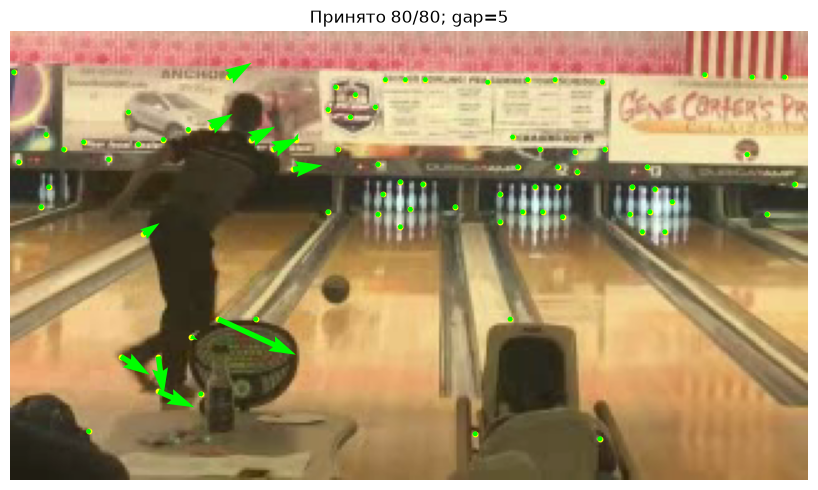

In [5]:
clip, frame, gap = "bowling", 30, 5  # Можно выбрать archery, gap=1 или gap=5.
capture = cv2.VideoCapture(str(DATA / f"{clip}.mp4"))
try:
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame)  # Индекс первого кадра.
    ok_first, first = capture.read()
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame + gap)  # Индекс второго кадра.
    ok_second, second = capture.read()
finally:
    capture.release()  # Освобождаем файл даже при ошибке чтения.
if not (ok_first and ok_second):
    raise ValueError("Не удалось прочитать выбранную пару кадров")
previous = cv2.cvtColor(first, cv2.COLOR_BGR2GRAY)  # BGR → один канал яркости.
current = cv2.cvtColor(second, cv2.COLOR_BGR2GRAY)
points = cv2.goodFeaturesToTrack(
    previous, maxCorners=80, qualityLevel=0.02, minDistance=8,
)
if points is None:
    raise ValueError("Не найдены характерные точки")
next_points, status, error = cv2.calcOpticalFlowPyrLK(
    previous, current, points, None,
    winSize=(21, 21), maxLevel=3,  # Локальное окно и разрешённые уровни 0…3.
    criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01),
)
valid = status.ravel() == 1
start, end = points[valid, 0], next_points[valid, 0]
movement = end - start
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(first, cv2.COLOR_BGR2RGB))  # RGB нужен для Matplotlib.
plt.scatter(start[:, 0], start[:, 1], s=10, c="yellow")
plt.quiver(start[:, 0], start[:, 1], movement[:, 0], movement[:, 1],
           angles="xy", scale_units="xy", scale=1, color="lime")
plt.title(f"Принято {valid.sum()}/{len(points)}; gap={gap}")
plt.axis("off")
plt.tight_layout()
plt.show()

## Проверка вперёд–назад

Запустим тот же метод из найденных позиций второго кадра обратно в первый. Оставим точки с принятым обратным поиском и ошибкой возврата меньше 1 px. Малая ошибка означает согласованность, но не гарантирует истинное соответствие. Повторяющаяся текстура может обмануть оба направления.

До проверки: 80, после: 68


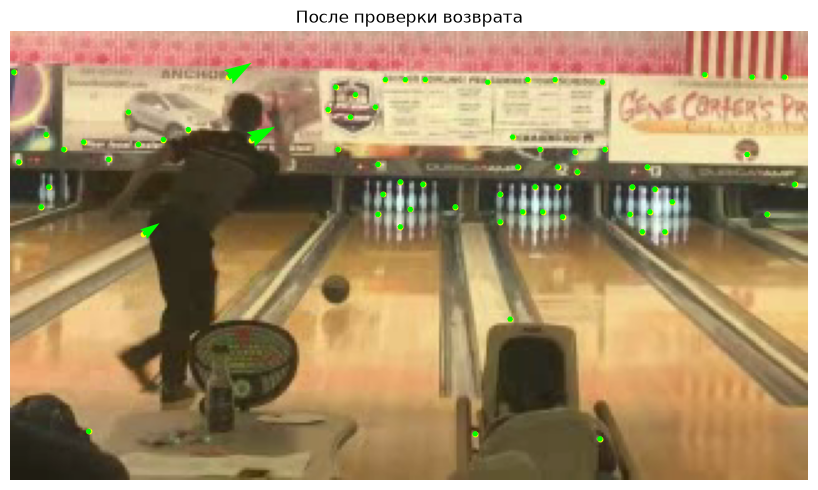

In [6]:
# Используем результат предыдущей ячейки с видео.
indices = np.flatnonzero(valid)
consistent = np.zeros(len(points), dtype=bool)
if len(indices):
    returned, back_status, _ = cv2.calcOpticalFlowPyrLK(
        current, previous,           # Обратный порядок кадров.
        next_points[indices], None,  # Стартуем с найденных позиций второго кадра.
        winSize=(21, 21), maxLevel=3,
        criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01),
    )
    return_error = np.linalg.norm(returned[:, 0] - points[indices, 0], axis=1)
    consistent[indices] = (back_status.ravel() == 1) & (return_error < 1)
print(f"До проверки: {valid.sum()}, после: {consistent.sum()}")
start, end = points[consistent, 0], next_points[consistent, 0]
movement = end - start
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(first, cv2.COLOR_BGR2RGB))
plt.scatter(start[:, 0], start[:, 1], s=10, c="yellow")
plt.quiver(start[:, 0], start[:, 1], movement[:, 0], movement[:, 1],
           angles="xy", scale_units="xy", scale=1, color="lime")
plt.title("После проверки возврата")
plt.axis("off")
plt.tight_layout()
plt.show()

## Видео целиком

Два готовых ролика: боулинг и стрельба из лука. Слева — OpenCV без пирамиды (L0), справа — с пирамидой (L3). Жёлтые точки — исходные позиции, зелёные стрелки — смещения в масштабе 1:1.

В этих роликах `gap=5`: движение измеряется через пять исходных кадров, чтобы стрелки были заметнее. Точки выбираются заново для каждой пары; это не непрерывные траектории. Нажмите ▶ в плеере. Для соседних кадров замените `gap=5` на `gap=1` в ячейке ниже.

In [7]:
from IPython.display import Video, Markdown, display

gap = 5  # Интервал между исходными кадрами; 1 — соседние кадры.
for clip in ["bowling", "archery"]:
    path = OUTPUTS / f"{clip}_gap{gap}.mp4"
    display(Markdown(f"**{clip}: OpenCV L0 / L3, gap={gap}**"))
    # embed=True сохраняет ролик внутри notebook, width задаёт ширину плеера.
    display(Video(str(path), embed=True, width=640))

**bowling: OpenCV L0 / L3, gap=5**

**archery: OpenCV L0 / L3, gap=5**

## Источники

- [Оптический поток в OpenCV](https://docs.opencv.org/4.x/d4/dee/tutorial_optical_flow.html).
- [Параметры PyrLK](https://docs.opencv.org/4.x/dc/d6b/group__video__track.html).

Далее: [плотный поток](../dense_optical_flow_lesson/lesson.ipynb) и [FlowNet](../flownet_lesson/lesson.ipynb).